# 6. Diagnóstico de residuos

**Objetivo del capítulo.** Comprobar si los errores del MLP son ruido sin estructura o si queda dependencia
temporal que el modelo no captó. Se aplica el **test BDS** (Brock, Dechert y Scheinkman) a los residuos del
primer paso del horizonte (h = 1), `resid = y_real − y_predicho`, en cada fold de validación de las tres
estrategias y en el hold-out del modelo final.

* H0 del BDS: los residuos son independientes e idénticamente distribuidos (iid).
* p > 0,05 → no se rechaza iid (buena señal); p ≤ 0,05 → queda dependencia (lineal o no lineal).

Se usa `statsmodels.tsa.stattools.bds` con dimensión de inmersión 2 (el borrador de la guía lo importa desde
`arch.bootstrap`, pero ese módulo no lo trae).

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from scipy import stats
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox

from fcst.cv import STRATEGY_LABEL
from fcst.features import holdout_split
from fcst.metrics import bds_pvalue
from fcst.nbutils import INK2, MUTED, SERIES, STRAT_COLOR, plt, savefig, setup

cfg, RES, FIG = setup()
series = pd.read_csv(RES / "serie_modelado.csv", parse_dates=["Date"])
y, dates = series.Close.values, series.Date
sp = holdout_split(len(y), cfg["holdout_frac"], cfg["horizons"])
LAGS, HS, STRATS = cfg["lags"], cfg["horizons"], cfg["cv"]["strategies"]
pf = pd.read_csv(RES / "cv_metricas_por_fold.csv")
dep = pd.read_csv(RES / "modelos_desplegados.csv")

Perfil: full  |  resultados en: /content/deep-learning-02-forecasting-mlp/results


## 6.1 p-valores BDS en validación (por estrategia, lag y horizonte)

In [2]:
mlp = pf[pf.modelo == "mlp"]
bds_tab = mlp.groupby(["estrategia", "lag", "H"]).agg(
    BDS_p_medio=("BDS_pvalue_h1", "mean"), folds=("fold", "count"),
    folds_iid=("BDS_pvalue_h1", lambda s: int((s > 0.05).sum()))).reset_index()
bds_tab["estrategia"] = bds_tab.estrategia.map(STRATEGY_LABEL)
bds_tab.to_csv(RES / "bds_validacion.csv", index=False)
piv = bds_tab.pivot_table(index=["estrategia", "lag"], columns="H", values="BDS_p_medio")
piv.columns = [f"H = {h}" for h in piv.columns]
display(Markdown("**p-valor BDS medio de h = 1 en validación** (celdas > 0,05 = no se rechaza iid)"))
piv.style.format("{:.3f}").map(lambda v: "font-weight:bold" if v > 0.05 else "")

**p-valor BDS medio de h = 1 en validación** (celdas > 0,05 = no se rechaza iid)

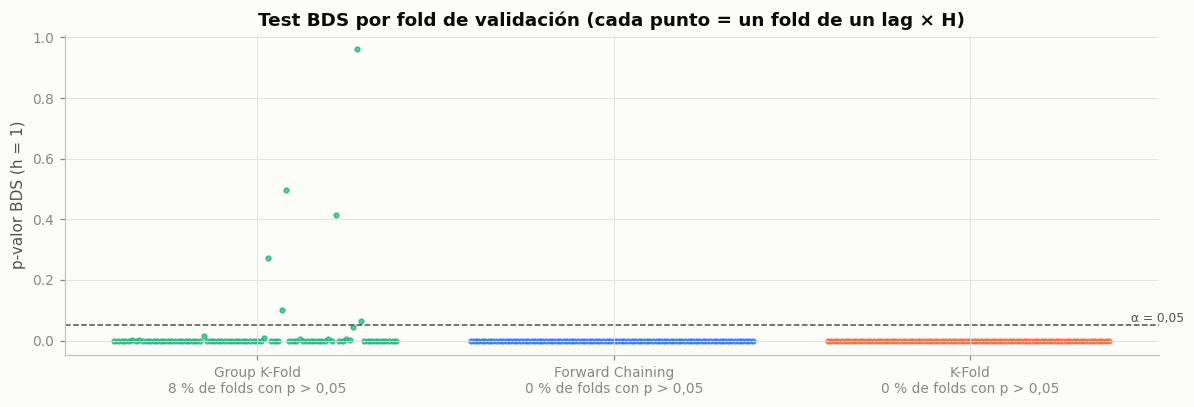

In [3]:
share = mlp.assign(iid=mlp.BDS_pvalue_h1 > 0.05).groupby("estrategia").iid.mean().rename(index=STRATEGY_LABEL)
fig, ax = plt.subplots(figsize=(11, 3.8))
for i, st in enumerate(STRATS):
    d = mlp[mlp.estrategia == st]
    xs = np.arange(len(d)) / len(d) * 0.8 + i - 0.4
    ax.scatter(xs, d.BDS_pvalue_h1, s=10, color=STRAT_COLOR[st], alpha=0.7)
ax.axhline(0.05, color=INK2, ls="--", lw=1)
ax.text(2.45, 0.06, "α = 0,05", color=INK2, fontsize=8)
ax.set_xticks(range(len(STRATS)), [f"{STRATEGY_LABEL[s]}\n{100 * share[STRATEGY_LABEL[s]]:.0f} % de folds con p > 0,05" for s in STRATS])
ax.set_ylabel("p-valor BDS (h = 1)"); ax.set_title("Test BDS por fold de validación (cada punto = un fold de un lag × H)")
savefig(fig, FIG, "06_bds_por_estrategia")
plt.show()

## 6.2 Residuos de los modelos desplegados en el hold-out

In [4]:
z = np.load(RES / "preds" / "holdout_final.npz")   # predicciones del capítulo 5
rows, resids = [], {}
for r in dep.itertuples():
    k = f"l{r.lag}_h{r.H}__"
    e = z[k + "y_hold"][:, 0] - z[k + "p_hold"][:, 0]
    resids[r.H] = (z[k + "hold_idx"], e)
    lb = acorr_ljungbox(e, lags=[10], return_df=True).iloc[0]
    rows.append({"H": r.H, "lag": r.lag, "n": len(e), "media_resid": e.mean(), "desv_resid": e.std(),
                 "BDS_pvalue_h1": bds_pvalue(e), "LjungBox10_p": lb.lb_pvalue,
                 "Shapiro_p": stats.shapiro(e[:5000]).pvalue})
res_hold = pd.DataFrame(rows)
res_hold.to_csv(RES / "residuos_holdout.csv", index=False)
res_hold.style.format({"media_resid": "{:,.0f}", "desv_resid": "{:,.0f}", "BDS_pvalue_h1": "{:.3f}",
                       "LjungBox10_p": "{:.3f}", "Shapiro_p": "{:.3f}"}).hide(axis="index")

H,lag,n,media_resid,desv_resid,BDS_pvalue_h1,LjungBox10_p,Shapiro_p
7,21,316,"-4,209","3,138",0.000,0.000,0.000
14,7,309,-106,"2,875",0.000,0.000,0.019
21,7,302,194,"2,818",0.000,0.000,0.002
28,7,295,"5,703","3,808",0.000,0.000,0.003


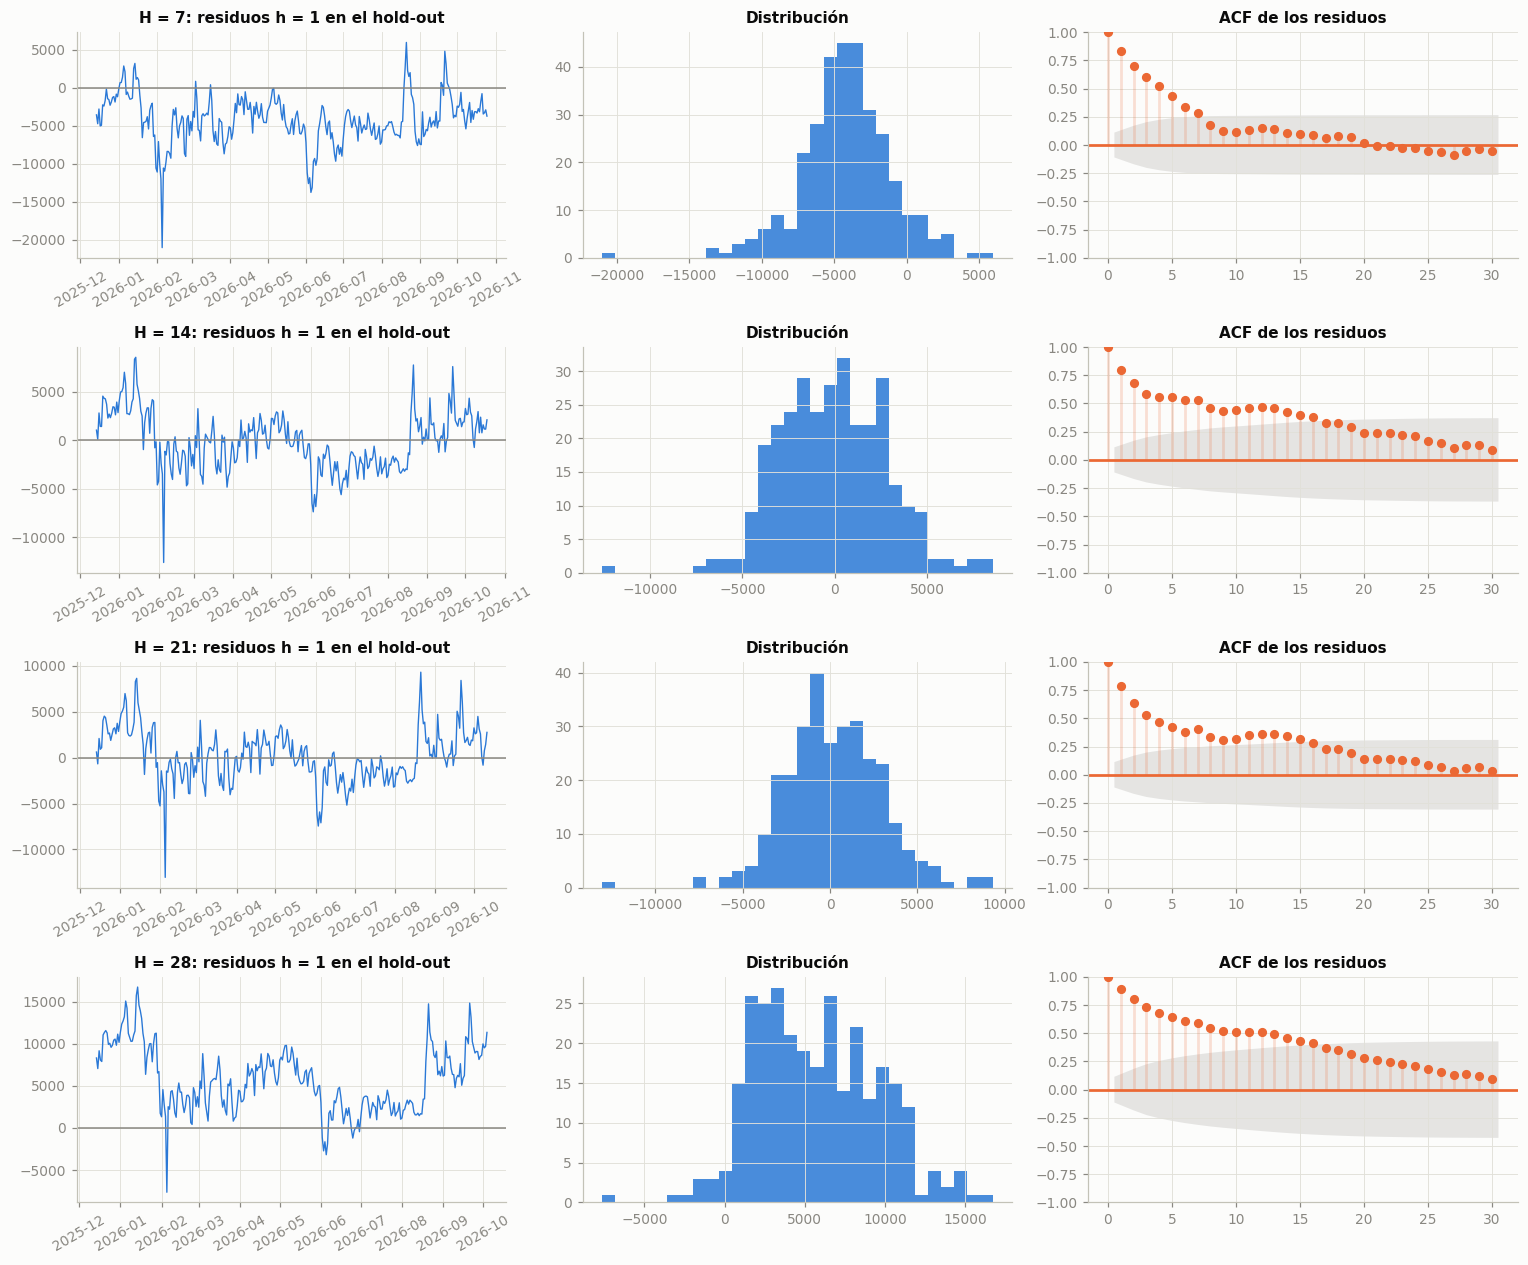

In [5]:
fig, axes = plt.subplots(len(resids), 3, figsize=(14, 2.9 * len(resids)))
for i, (H, (idx, e)) in enumerate(resids.items()):
    ax = axes[i, 0]
    ax.plot(dates.iloc[idx], e, color=SERIES[0], lw=0.9); ax.axhline(0, color=MUTED, lw=1)
    ax.set_title(f"H = {H}: residuos h = 1 en el hold-out", fontsize=10); ax.tick_params(axis="x", labelrotation=30)
    ax = axes[i, 1]
    ax.hist(e, bins=30, color=SERIES[0], alpha=0.85); ax.set_title("Distribución", fontsize=10)
    plot_acf(e, lags=min(30, len(e) // 3), ax=axes[i, 2], color=SERIES[1], vlines_kwargs={"colors": SERIES[1]})
    axes[i, 2].set_title("ACF de los residuos", fontsize=10)
    for c in axes[i, 2].collections:
        c.set_facecolor(MUTED); c.set_alpha(0.2)
savefig(fig, FIG, "06_residuos_holdout")
plt.show()

In [6]:
p_fc = share.get("Forward Chaining", np.nan)
display(Markdown(
    f"**Lectura automática.** En Forward Chaining, {100 * p_fc:.0f} % de los folds no rechazan iid en el BDS. "
    f"En el hold-out, {int((res_hold.BDS_pvalue_h1 > 0.05).sum())} de {len(res_hold)} modelos desplegados tienen "
    "residuos compatibles con iid. Una media de residuos lejos de cero indica sesgo sistemático (p. ej. el modelo "
    "se queda por debajo cuando el precio sube a niveles no vistos); un BDS que rechaza iid indica dependencia "
    "remanente, coherente con la agrupación de la volatilidad vista en el capítulo 1."))

**Lectura automática.** En Forward Chaining, 0 % de los folds no rechazan iid en el BDS. En el hold-out, 0 de 4 modelos desplegados tienen residuos compatibles con iid. Una media de residuos lejos de cero indica sesgo sistemático (p. ej. el modelo se queda por debajo cuando el precio sube a niveles no vistos); un BDS que rechaza iid indica dependencia remanente, coherente con la agrupación de la volatilidad vista en el capítulo 1.